In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
df_ratings = pd.read_csv('../results/hotel_stats_ratings.csv')
df_pred    = pd.read_csv('../results/hotel_reviews_with_predictions.csv')

=== TOP 10 — Système Sentiments (DistilBERT) ===
                           Hotel_Name  nb_avis_sent  score_sentiment_moy  pct_positif  pct_negatif
                Hotel du Petit Moulin            66                0.962         92.4          0.0
                                   41           103                0.961         92.2          0.0
    Hollmann Beletage Design Boutique           102                0.956         92.2          1.0
           Milestone Hotel Kensington            86                0.953         91.9          1.2
                    Hotel Casa Camper           301                0.952         91.0          0.7
                         H tel Fabric           103                0.951         90.3          0.0
Pillows Anna van den Vondel Amsterdam            56                0.946         91.1          1.8
                       The Soho Hotel           157                0.939         88.5          0.6
                    Hotel Sacher Wien           130         

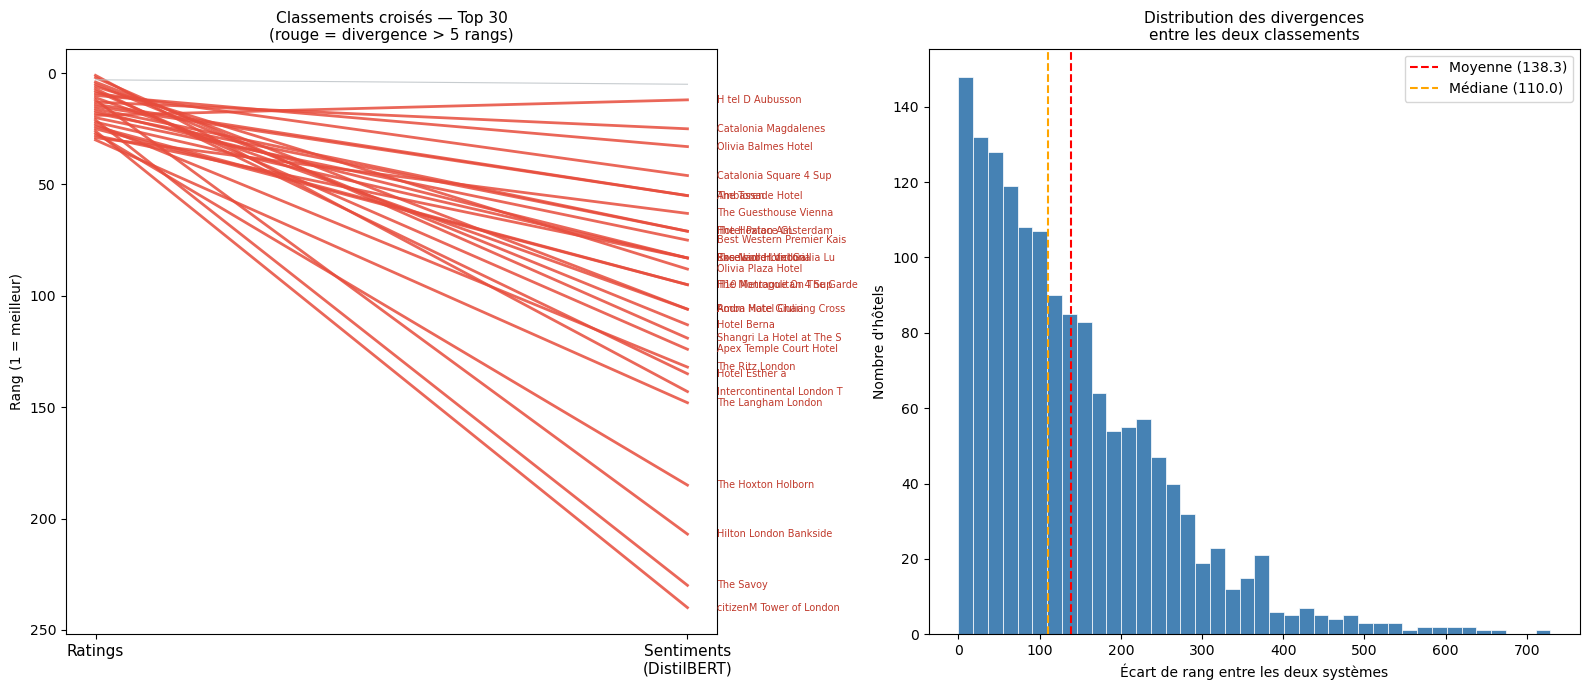

✅ Graphique sauvegardé
✅ Comparaison sauvegardée : results/comparaison_systemes.csv


In [3]:

# ════════════════════════════════════════════════════════════
# 2. SCORE SENTIMENT PAR HÔTEL (depuis DistilBERT)
# ════════════════════════════════════════════════════════════
label_to_score = {'Positive': 1.0, 'Neutral': 0.5, 'Negative': 0.0}
df_pred['score_sentiment'] = df_pred['distilbert_sentiment'].map(label_to_score)

hotel_sentiment = df_pred.groupby('hotel').agg(
    nb_avis_sent        = ('score_sentiment', 'count'),
    score_sentiment_moy = ('score_sentiment', 'mean'),
    pct_positif         = ('distilbert_sentiment', lambda x: (x == 'Positive').mean() * 100),
    pct_negatif         = ('distilbert_sentiment', lambda x: (x == 'Negative').mean() * 100),
    pct_neutre          = ('distilbert_sentiment', lambda x: (x == 'Neutral').mean() * 100),
).reset_index()

hotel_sentiment.rename(columns={'hotel': 'Hotel_Name'}, inplace=True)
hotel_sentiment['score_sentiment_moy'] = hotel_sentiment['score_sentiment_moy'].round(3)
hotel_sentiment['pct_positif']         = hotel_sentiment['pct_positif'].round(1)
hotel_sentiment['pct_negatif']         = hotel_sentiment['pct_negatif'].round(1)
hotel_sentiment['rang_sentiments']     = hotel_sentiment['score_sentiment_moy']\
                                         .rank(ascending=False).astype(int)

print("=== TOP 10 — Système Sentiments (DistilBERT) ===")
print(hotel_sentiment.sort_values('score_sentiment_moy', ascending=False)
      [['Hotel_Name', 'nb_avis_sent', 'score_sentiment_moy', 'pct_positif', 'pct_negatif']]
      .head(10).to_string(index=False))

# ════════════════════════════════════════════════════════════
# 3. FUSION DES DEUX CLASSEMENTS
# ════════════════════════════════════════════════════════════
comparaison = df_ratings[['Hotel_Name', 'rang_ratings', 'score_bayes', 'nb_avis']] \
              .merge(hotel_sentiment, on='Hotel_Name', how='inner')

comparaison['diff_rang'] = (
    comparaison['rang_ratings'] - comparaison['rang_sentiments']
).abs()

print(f"\nNombre d'hôtels en commun : {len(comparaison)}")
print("\nAperçu de la table de comparaison :")
print(comparaison[['Hotel_Name', 'rang_ratings', 'rang_sentiments',
                    'score_bayes', 'score_sentiment_moy', 'diff_rang']]
      .head(10).to_string(index=False))

# ════════════════════════════════════════════════════════════
# 4. CORRÉLATION DE SPEARMAN
# ════════════════════════════════════════════════════════════
corr, pval = stats.spearmanr(
    comparaison['rang_ratings'],
    comparaison['rang_sentiments']
)
print(f"\n📊 Corrélation de Spearman : {corr:.3f}  (p = {pval:.4f})")

if corr >= 0.8:
    interp = "Les deux systèmes sont très similaires → le texte confirme les notes"
elif corr >= 0.6:
    interp = "Corrélation modérée → des divergences existent, le texte apporte de l'info supplémentaire"
else:
    interp = "Faible corrélation → les deux systèmes sont très différents, le texte est plus informatif que la note"
print(f"→ {interp}")

# ════════════════════════════════════════════════════════════
# 5. HÔTELS LES PLUS DIVERGENTS
# ════════════════════════════════════════════════════════════
print("\n=== TOP 10 hôtels avec classements les plus divergents ===")
divergents = comparaison.nlargest(10, 'diff_rang')[
    ['Hotel_Name', 'rang_ratings', 'rang_sentiments',
     'diff_rang', 'score_bayes', 'pct_positif', 'pct_negatif']
]
print(divergents.to_string(index=False))

# ════════════════════════════════════════════════════════════
# 6. STATISTIQUES GLOBALES DE DIVERGENCE
# ════════════════════════════════════════════════════════════
print("\n=== STATISTIQUES DE DIVERGENCE ===")
print(f"Divergence moyenne  : {comparaison['diff_rang'].mean():.1f} rangs")
print(f"Divergence médiane  : {comparaison['diff_rang'].median():.1f} rangs")
print(f"Divergence max      : {comparaison['diff_rang'].max():.0f} rangs")
print(f"Hôtels divergeant > 50 rangs  : {(comparaison['diff_rang'] > 50).sum()}")
print(f"Hôtels divergeant > 100 rangs : {(comparaison['diff_rang'] > 100).sum()}")

# ════════════════════════════════════════════════════════════
# 7. VISUALISATION — Bump chart + Distribution divergences
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# -- Graphique 1 : Bump chart Top 30 --
ax1 = axes[0]
top30 = comparaison.nsmallest(30, 'rang_ratings').copy()

for _, row in top30.iterrows():
    divergence = abs(row['diff_rang'])
    couleur    = '#e74c3c' if divergence > 5 else '#bdc3c7'
    lw         = 2.0       if divergence > 5 else 0.8
    ax1.plot([1, 2],
             [row['rang_ratings'], row['rang_sentiments']],
             color=couleur, linewidth=lw, alpha=0.85)
    if divergence > 5:
        ax1.text(2.05, row['rang_sentiments'],
                 row['Hotel_Name'][:25],
                 fontsize=7, va='center', color='#c0392b')

ax1.set_xticks([1, 2])
ax1.set_xticklabels(['Ratings', 'Sentiments\n(DistilBERT)'], fontsize=11)
ax1.invert_yaxis()
ax1.set_ylabel("Rang (1 = meilleur)", fontsize=10)
ax1.set_title("Classements croisés — Top 30\n(rouge = divergence > 5 rangs)", fontsize=11)

# -- Graphique 2 : Distribution des divergences --
ax2 = axes[1]
ax2.hist(comparaison['diff_rang'], bins=40, color='steelblue',
         edgecolor='white', linewidth=0.5)
ax2.axvline(comparaison['diff_rang'].mean(),   color='red',
            linestyle='--', linewidth=1.5,
            label=f"Moyenne ({comparaison['diff_rang'].mean():.1f})")
ax2.axvline(comparaison['diff_rang'].median(), color='orange',
            linestyle='--', linewidth=1.5,
            label=f"Médiane ({comparaison['diff_rang'].median():.1f})")
ax2.set_xlabel("Écart de rang entre les deux systèmes")
ax2.set_ylabel("Nombre d'hôtels")
ax2.set_title("Distribution des divergences\nentre les deux classements", fontsize=11)
ax2.legend()

plt.tight_layout()
plt.savefig('../results/visualizations/comparaison_classements.png', dpi=150)
plt.show()
print("✅ Graphique sauvegardé")

# ════════════════════════════════════════════════════════════
# 8. SAUVEGARDE
# ════════════════════════════════════════════════════════════
comparaison.to_csv('../results/comparaison_systemes.csv', index=False)
print("✅ Comparaison sauvegardée : results/comparaison_systemes.csv")